In [14]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, Input, Dropout

In [4]:
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.cifar10.load_data()
)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1429s 8us/step


In [5]:
print("Training images:", X_train.shape)
print("Testing images", X_test.shape)

Training images: (50000, 32, 32, 3)
Testing images (10000, 32, 32, 3)


In [6]:
class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

In [7]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

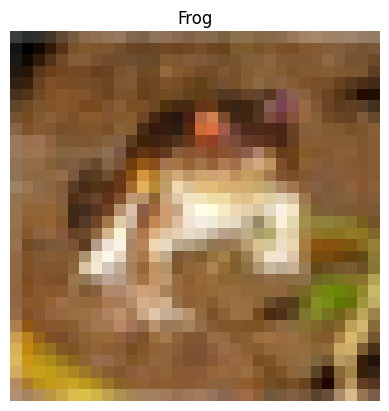

In [9]:
plt.imshow(X_train[0])
plt.title(class_names[int(y_train[0][0])])
plt.axis("off")
plt.show()

In [15]:
model = Sequential([Input(shape=(32, 32, 3)),
                           Conv2D(32, (3, 3), activation="relu", padding="same"),
                           MaxPooling2D((2, 2)),
                           Conv2D(64, (3, 3), activation="relu", padding="same"),
                           MaxPooling2D((2, 2)),
                           Conv2D(128, (3, 3), activation="relu", padding="same"),
                           MaxPooling2D((2, 2)),
                           Flatten(),
                           Dense(128, activation="relu"),
                           Dropout(0.3),
                           Dense(10, activation="softmax")

                           ])

In [16]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
history = model.fit(X_train, y_train, epochs=10, batch_size=64, validation_split=0.2)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 87s 136ms/step - accuracy: 0.4113 - loss: 1.6038 - val_accuracy: 0.5518 - val_loss: 1.2494
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 161s 167ms/step - accuracy: 0.5768 - loss: 1.1933 - val_accuracy: 0.6338 - val_loss: 1.0372
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 140s 165ms/step - accuracy: 0.6453 - loss: 1.0082 - val_accuracy: 0.6782 - val_loss: 0.9157
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 98s 158ms/step - accuracy: 0.6894 - loss: 0.8894 - val_accuracy: 0.6984 - val_loss: 0.8622
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 100s 160ms/step - accuracy: 0.7166 - loss: 0.8067 - val_accuracy: 0.7214 - val_loss: 0.7972
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 114s 182ms/step - accuracy: 0.7466 - loss: 0.7255 - val_accuracy: 0.7284 - val_loss: 0.7728
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 107s 172ms/step - accuracy: 0.7714 - loss: 0.6595 - val_accuracy: 0.7382 - val_loss: 0.7816
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 125s 144ms/step - accuracy: 0.7867 - l

In [20]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.7416 - loss: 0.8133


In [22]:
print("Test loss:", test_loss)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Test loss: 0.8132904171943665
Test Accuracy: 74.16 %


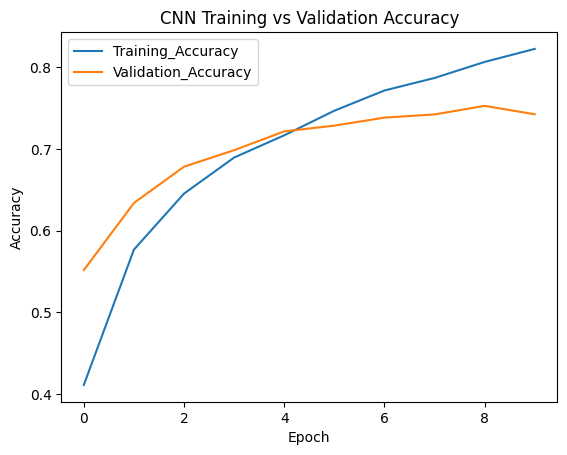

In [23]:
plt.plot(history.history["accuracy"], label="Training_Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation_Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training vs Validation Accuracy")
plt.legend()
plt.show()


In [24]:
image_index = 10
image = X_test[image_index]
image_batch = np.expand_dims(image, axis=0)
probabilities = model.predict(image_batch, verbose=0)
predicted_class = np.argmax(probabilities[0])
actual_class = int(y_test[image_index][0])

Text(0.5, 1.0, 'Predicted: Airplane\nActual: Airplane')

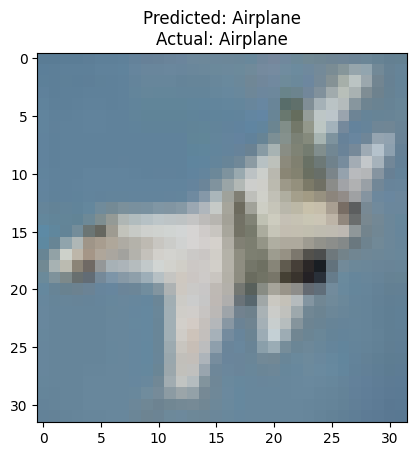

In [25]:
plt.imshow(image)
plt.title(f"Predicted: {class_names[predicted_class]}\n"
           f"Actual: {class_names[actual_class]}"
)

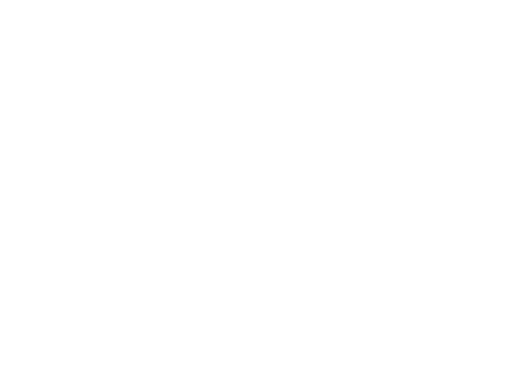

In [26]:
plt.axis("off")
plt.show()

In [27]:
print("Predicted Class:", class_names[predicted_class])
print("Actual Class:", class_names[actual_class])
print("prediction confidence:", round(float(np.max(probabilities[0]))*100, 2), "%")

Predicted Class: Airplane
Actual Class: Airplane
prediction confidence: 80.15 %
